# Member 3 — Logistic Regression, Random Forest, XGBoost
Module: `src/models_classical.py`. Hyper-parameters tuned with `RandomizedSearchCV` + `StratifiedGroupKFold(5)` on the training users, scored on PR-AUC.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
from src import config as C
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
def show(name): display(Image(filename=str(C.FIG_DIR / f'{name}.png')))
def tbl(name): return pd.read_csv(C.TABLE_DIR / f'{name}.csv')

In [2]:
import joblib
from src.features import prepare_dataset
from src.splits import get_split
from src.evaluation import evaluate
meta = json.loads((C.MODELS_DIR / 'model_meta.json').read_text())
df = prepare_dataset(); split = get_split(df); cols = meta['feature_columns']; y = df.is_fraud.values
print('feature set:', meta['feature_set']); json.dumps(meta['best_params'], indent=1)

feature set: T2_behavioural


'{\n "Logistic Regression": {\n  "strategy": "class_weight",\n  "cv_pr_auc": 0.8669,\n  "model__C": 100.0\n },\n "Random Forest": {\n  "strategy": "class_weight",\n  "cv_pr_auc": 0.948,\n  "model__n_estimators": 400,\n  "model__min_samples_leaf": 1,\n  "model__max_features": 0.5,\n  "model__max_depth": 8\n },\n "XGBoost": {\n  "strategy": "class_weight",\n  "cv_pr_auc": 0.9489,\n  "model__subsample": 1.0,\n  "model__n_estimators": 400,\n  "model__min_child_weight": 5,\n  "model__max_depth": 4,\n  "model__learning_rate": 0.03,\n  "model__colsample_bytree": 1.0\n }\n}'

## 1. Re-evaluate the saved tuned models on the test set

In [3]:
rows = []
for f, name in [('logreg','Logistic Regression'), ('random_forest','Random Forest'), ('xgboost','XGBoost')]:
    m = joblib.load(C.MODELS_DIR / f'{f}.joblib')
    pv = m.predict_proba(df.iloc[split['val']][cols])[:, 1]
    pt = m.predict_proba(df.iloc[split['test']][cols])[:, 1]
    r = evaluate(y[split['val']], pv, y[split['test']], pt); r['model'] = name; rows.append(r)
pd.DataFrame(rows).set_index('model')[['pr_auc','roc_auc','precision','recall','f1','fp','fn','threshold']].round(4)

,pr_auc,roc_auc,precision,recall,f1,fp,fn,threshold
model,,,,,,,,
Logistic Regression,0.8678,0.9182,0.8958,0.7529,0.8181,84,237,0.6622
Random Forest,0.9488,0.9709,0.9745,0.8759,0.9226,22,119,0.5801
XGBoost,0.9529,0.9740,0.9825,0.8790,0.9279,15,116,0.6880


## 2. Logistic Regression coefficients (standardised features)

In [4]:
lr = joblib.load(C.MODELS_DIR / 'logreg.joblib')
names = lr.named_steps['prep'].get_feature_names_out()
pd.Series(lr.named_steps['model'].coef_[0], index=names).sort_values(key=np.abs, ascending=False).round(3).to_frame('coef')

,coef
amount,2.625
input_timing_consistency,-0.611
session_duration,-0.538
input_pause_patterns,0.489
transaction_time_of_day,-0.469
request_amount_roundness,0.285
background_data_usage,0.283
keyboard_input_speed,-0.278
transaction_amount_vs_sender_history,0.267
app_switching_frequency,0.256


## 3. Experiment 2 — full comparison incl. deep models, bootstrap CI, hard subset

In [5]:
tbl('exp2_model_comparison')

,model,setting,val_pr_auc,pr_auc_ci_low,pr_auc_ci_high,hard_subset_pr_auc,roc_auc,pr_auc,precision,recall,f1,fpr,tp,fp,fn,tn,threshold,precision_at_val_recall90,recall_at_val_recall90,champion
0,Logistic Regression,T2 tuned,0.8456,0.8506,0.8859,0.2399,0.9182,0.8678,0.8958,0.7529,0.8181,0.0190,722,84,237,4331,0.6622,0.3107,0.9270,False
1,Random Forest,T2 tuned,0.9337,0.9372,0.9592,0.4034,0.9709,0.9488,0.9745,0.8759,0.9226,0.0050,840,22,119,4393,0.5801,0.6923,0.9197,False
2,XGBoost,T2 tuned,0.9373,0.9429,0.9626,0.4316,0.9740,0.9529,0.9825,0.8790,0.9279,0.0034,843,15,116,4400,0.6880,0.7170,0.9218,True
3,MLP,T2,0.9295,0.9304,0.9531,0.3899,0.9645,0.9420,0.9821,0.8571,0.9154,0.0034,822,15,137,4400,0.2099,0.6756,0.9166,False
4,LSTM,T2 sequences (k=5),0.9205,0.9171,0.9433,0.3437,0.9527,0.9305,0.9756,0.8342,0.8994,0.0045,800,20,159,4395,0.7513,0.5828,0.9135,False
5,Rule baseline,range rule,NaN,NaN,NaN,NaN,0.9144,0.8509,0.9876,0.8311,0.9026,0.0023,797,10,162,4405,0.5000,NaN,NaN,False


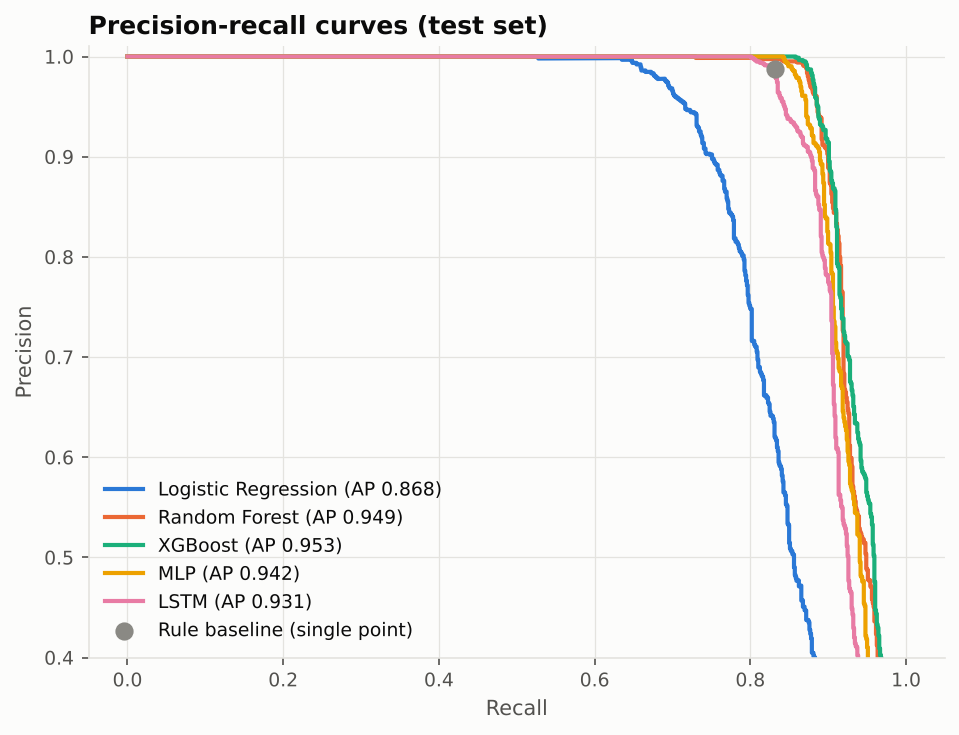

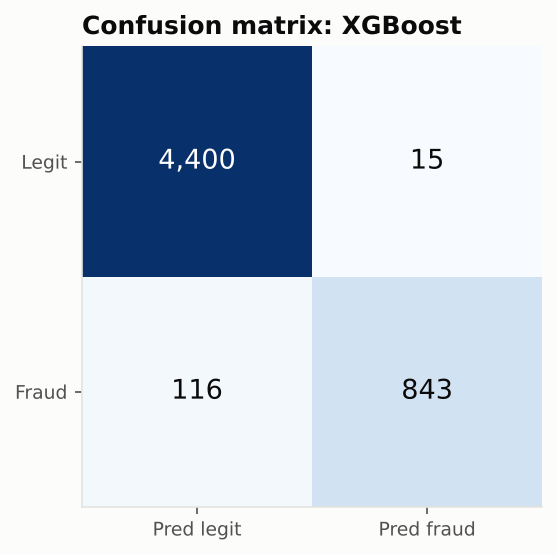

In [6]:
show('11_pr_curves'); show('16_confusion_matrix_champion')

## 4. Is the champion significantly better? (McNemar on test decisions)

In [7]:
tbl('exp2_mcnemar_tests')

,champion,versus,a_right_b_wrong,a_wrong_b_right,chi2,p_value
0,XGBoost,Logistic Regression,210,20,155.30870,0.00000
1,XGBoost,Random Forest,18,8,3.11538,0.07756
2,XGBoost,MLP,30,9,10.25641,0.00136
3,XGBoost,LSTM,63,15,28.32051,0.00000


## 5. Threshold & illustrative cost analysis

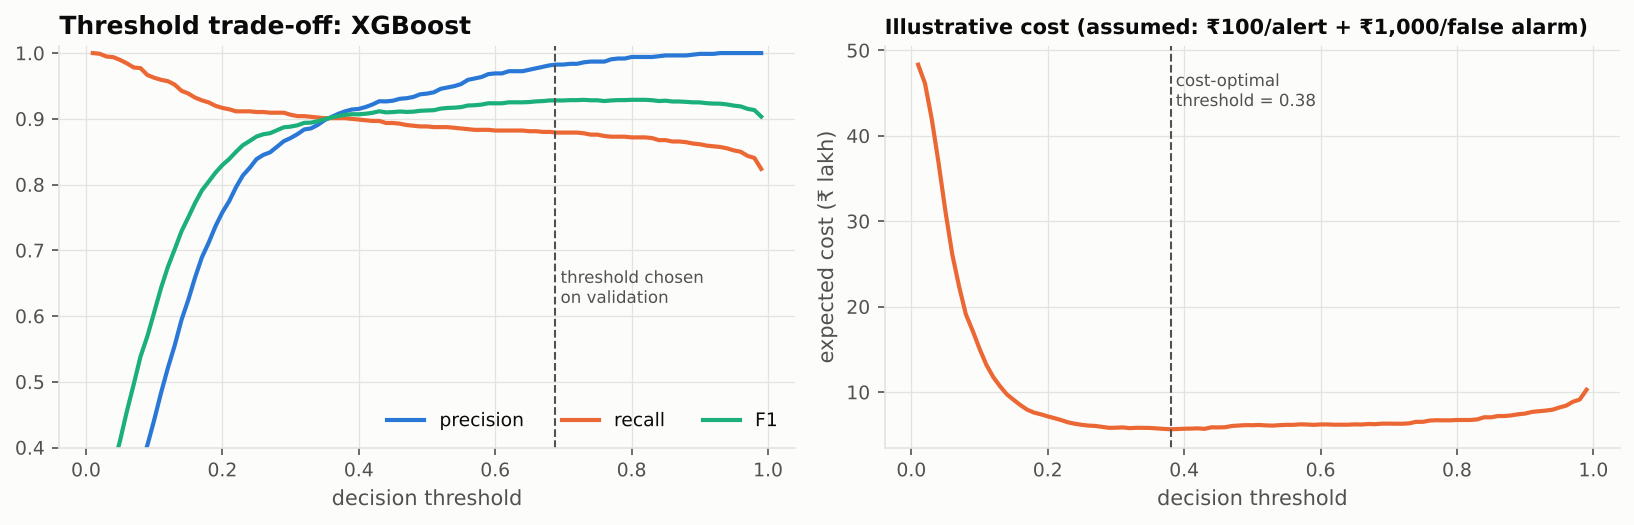

In [8]:
show('17_threshold_and_cost')